<div style="background-color: #e6f3ff; padding: 24px; border-radius: 12px; border: 1px solid #b3d8ff; color: #1a2530;">

# Heart Disease Prediction
**Statlog Heart Disease Dataset | Machine Learning Classification**

Exploratory data analysis, feature engineering, model training, and cost-sensitive evaluation.  
* **Dataset:** 270 observations · 13 predictors  
* **Task:** Binary classification

---

## Workflow

1. Load and validate the dataset.
2. Explore clinical and categorical attributes.
3. Prepare features without test-set leakage.
4. Train and compare classification algorithms.
5. Evaluate recall, precision, F1-score, ROC-AUC, and the cost matrix.

> **Educational use only:** This historical, small dataset is not a medical diagnostic tool and must not be used for clinical decisions.


## 1. Import libraries
Load the core Python packages used throughout the notebook.

In [1]:
import os, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 120)
RANDOM_STATE = 42
print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Configure visual style
Examine the dataset and build the classification workflow step by step.

In [2]:
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.figsize": (9, 5), "axes.titlesize": 14,
                     "axes.labelsize": 11, "font.size": 10, "figure.dpi": 110})

## 3. Find available data files
Search common Kaggle and local locations for CSV, DAT, or TXT files.

In [3]:
roots = [Path("/kaggle/input"), Path(".")]
files = []
for root in roots:
    if root.exists():
        for pattern in ("**/*.csv", "**/*.dat", "**/*.txt"):
            files.extend(root.glob(pattern))
files = sorted(set(files))
print("Candidate files:", len(files))
for path in files[:30]:
    print(path)

Candidate files: 1
/kaggle/input/datasets/ritwikb3/heart-disease-statlog/Heart_disease_statlog.csv


## 4. Select the heart dataset
Examine the dataset and build the classification workflow step by step.

In [4]:
heart_files = [p for p in files if "heart" in p.name.lower()]
if not heart_files:
    raise FileNotFoundError("Heart dataset not found. Attach the Kaggle dataset or set DATA_FILE manually.")
DATA_FILE = heart_files[0]
print("Selected:", DATA_FILE)

Selected: /kaggle/input/datasets/ritwikb3/heart-disease-statlog/Heart_disease_statlog.csv


## 5. Define the Statlog schema
Examine the dataset and build the classification workflow step by step.

In [5]:
COLUMN_NAMES = ["age","sex","cp","trestbps","chol","fbs","restecg",
                 "thalach","exang","oldpeak","slope","ca","thal","target"]
print("Expected columns:", len(COLUMN_NAMES))
print(COLUMN_NAMES)

Expected columns: 14
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']


## 6. Load the raw dataset
The original Statlog file is often whitespace-separated `heart.dat`; some copies are CSV files.

In [6]:
def load_heart_data(path):
    path = Path(path)
    if path.suffix.lower() == ".csv":
        data = pd.read_csv(path)
        normalized = [str(c).strip().lower() for c in data.columns]
        if data.shape[1] == 14 and not set(COLUMN_NAMES).issubset(set(normalized)):
            data.columns = COLUMN_NAMES
        return data
    data = pd.read_csv(path, sep=r"\s+", header=None, engine="python")
    if data.shape[1] != 14:
        raise ValueError(f"Expected 14 columns; found {data.shape[1]}.")
    data.columns = COLUMN_NAMES
    return data

raw_df = load_heart_data(DATA_FILE)
print("Shape:", raw_df.shape)
display(raw_df.head())

Shape: (270, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,70,1,3,130,322,0,2,109,0,2.4,1,3,1,1
1,67,0,2,115,564,0,2,160,0,1.6,1,0,3,0
2,57,1,1,124,261,0,0,141,0,0.3,0,0,3,1
3,64,1,3,128,263,0,0,105,1,0.2,1,1,3,0
4,74,0,1,120,269,0,2,121,1,0.2,0,1,1,0


## 7. Standardize column names
Examine the dataset and build the classification workflow step by step.

In [7]:
df = raw_df.copy()
df.columns = [str(c).strip().lower().replace(" ", "_") for c in df.columns]
print(df.columns.tolist())

['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']


## 8. Dataset dimensions and types
Examine the dataset and build the classification workflow step by step.

In [8]:
print("Rows:", df.shape[0], "| Columns:", df.shape[1])
display(df.dtypes.to_frame("data_type"))

Rows: 270 | Columns: 14


,data_type
age,int64
sex,int64
cp,int64
trestbps,int64
chol,int64
fbs,int64
restecg,int64
thalach,int64
exang,int64
oldpeak,float64


## 9. Preview the observations
Examine the dataset and build the classification workflow step by step.

In [9]:
display(df.head(10))
display(df.tail(5))

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,70,1,3,130,322,0,2,109,0,2.4,1,3,1,1
1,67,0,2,115,564,0,2,160,0,1.6,1,0,3,0
2,57,1,1,124,261,0,0,141,0,0.3,0,0,3,1
3,64,1,3,128,263,0,0,105,1,0.2,1,1,3,0
4,74,0,1,120,269,0,2,121,1,0.2,0,1,1,0
5,65,1,3,120,177,0,0,140,0,0.4,0,0,3,0
6,56,1,2,130,256,1,2,142,1,0.6,1,1,2,1
7,59,1,3,110,239,0,2,142,1,1.2,1,1,3,1
8,60,1,3,140,293,0,2,170,0,1.2,1,2,3,1
9,63,0,3,150,407,0,2,154,0,4.0,1,3,3,1


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
265,52,1,2,172,199,1,0,162,0,0.5,0,0,3,0
266,44,1,1,120,263,0,0,173,0,0.0,0,0,3,0
267,56,0,1,140,294,0,2,153,0,1.3,1,0,1,0
268,57,1,3,140,192,0,0,148,0,0.4,1,0,2,0
269,67,1,3,160,286,0,2,108,1,1.5,1,3,1,1


## 10. Statistical summary
Examine the dataset and build the classification workflow step by step.

In [10]:
display(df.describe(include="all").T)

,count,mean,std,min,25%,50%,75%,max
age,270.0,54.433333,9.109067,29.0,48.0,55.0,61.0,77.0
sex,270.0,0.677778,0.468195,0.0,0.0,1.0,1.0,1.0
cp,270.0,2.174074,0.950090,0.0,2.0,2.0,3.0,3.0
trestbps,270.0,131.344444,17.861608,94.0,120.0,130.0,140.0,200.0
chol,270.0,249.659259,51.686237,126.0,213.0,245.0,280.0,564.0
fbs,270.0,0.148148,0.355906,0.0,0.0,0.0,0.0,1.0
restecg,270.0,1.022222,0.997891,0.0,0.0,2.0,2.0,2.0
thalach,270.0,149.677778,23.165717,71.0,133.0,153.5,166.0,202.0
exang,270.0,0.329630,0.470952,0.0,0.0,0.0,1.0,1.0
oldpeak,270.0,1.050000,1.145210,0.0,0.0,0.8,1.6,6.2


## 11. Validate expected columns
Examine the dataset and build the classification workflow step by step.

In [11]:
missing_cols = sorted(set(COLUMN_NAMES) - set(df.columns))
extra_cols = sorted(set(df.columns) - set(COLUMN_NAMES))
print("Missing expected columns:", missing_cols)
print("Extra columns:", extra_cols)
if missing_cols:
    raise ValueError("Column names do not match the expected Statlog schema.")

Missing expected columns: []
Extra columns: []


## 12. Audit missing values
Examine the dataset and build the classification workflow step by step.

In [12]:
missing_report = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
}).sort_values("missing_count", ascending=False)
display(missing_report)

,missing_count,missing_percent
age,0,0.0
sex,0,0.0
cp,0,0.0
trestbps,0,0.0
chol,0,0.0
fbs,0,0.0
restecg,0,0.0
thalach,0,0.0
exang,0,0.0
oldpeak,0,0.0


## 13. Check duplicate records
Examine the dataset and build the classification workflow step by step.

In [13]:
duplicate_count = int(df.duplicated().sum())
print("Duplicate rows:", duplicate_count)

Duplicate rows: 0


## 14. Convert fields to numeric
Examine the dataset and build the classification workflow step by step.

In [14]:
for col in COLUMN_NAMES:
    df[col] = pd.to_numeric(df[col], errors="coerce")
print("Missing values after numeric conversion:", int(df.isna().sum().sum()))

Missing values after numeric conversion: 0


## 15. Clean invalid records
Examine the dataset and build the classification workflow step by step.

In [15]:
rows_before = len(df)
df = df.drop_duplicates().dropna().reset_index(drop=True)
print("Rows before:", rows_before)
print("Rows after:", len(df))
print("Rows removed:", rows_before - len(df))

Rows before: 270
Rows after: 270
Rows removed: 0


## 16. Inspect target encoding
The original target often uses 1 = absence and 2 = presence; some copies use 0 and 1.

In [16]:
print("Unique target labels:", sorted(df.target.unique().tolist()))
display(df.target.value_counts(dropna=False).sort_index().to_frame("count"))

Unique target labels: [0, 1]


,count
target,
0,150
1,120


## 17. Map target to binary labels
Examine the dataset and build the classification workflow step by step.

In [17]:
labels = set(df.target.unique())
if labels == {1, 2}:
    df["target"] = df.target.map({1: 0, 2: 1})
elif labels == {0, 1}:
    df["target"] = df.target.astype(int)
else:
    raise ValueError(f"Unexpected target encoding: {labels}")
df["target"] = df.target.astype(int)
print("Target: 0 = absence, 1 = presence")
display(df.target.value_counts().rename(index={0:"Absence",1:"Presence"}).to_frame("count"))

Target: 0 = absence, 1 = presence


,count
target,
Absence,150
Presence,120


## 18. Define feature groups
Examine the dataset and build the classification workflow step by step.

In [18]:
NUMERIC_FEATURES = ["age","trestbps","chol","thalach","oldpeak"]
CATEGORICAL_FEATURES = ["sex","cp","fbs","restecg","exang","slope","ca","thal"]
TARGET = "target"
print("Numeric:", NUMERIC_FEATURES)
print("Categorical:", CATEGORICAL_FEATURES)

Numeric: ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
Categorical: ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']


## 19. Visualize target balance
Examine the dataset and build the classification workflow step by step.

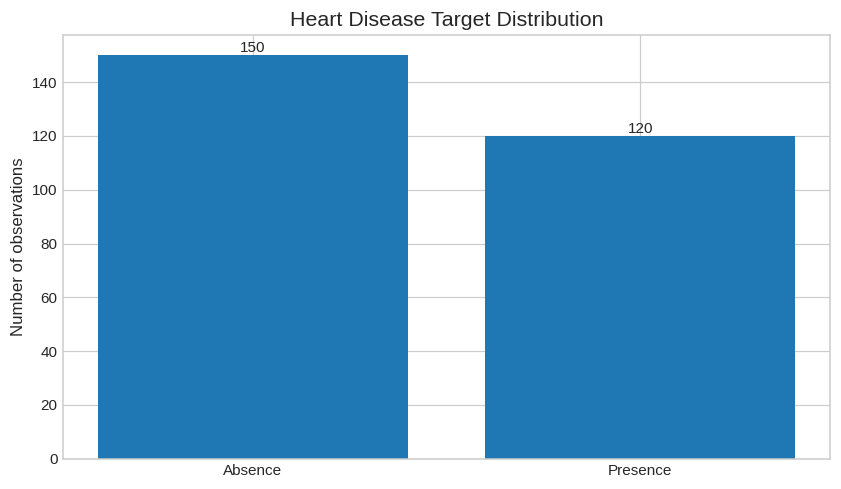

target
0    55.56
1    44.44
Name: percentage, dtype: float64

In [19]:
counts = df.target.value_counts().reindex([0,1], fill_value=0)
fig, ax = plt.subplots()
bars = ax.bar(["Absence","Presence"], counts.values)
ax.set_title("Heart Disease Target Distribution")
ax.set_ylabel("Number of observations")
for bar in bars:
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height(), str(int(bar.get_height())), ha="center", va="bottom")
plt.show()
display((df.target.value_counts(normalize=True)*100).round(2).rename("percentage"))

## 20. Compare numeric summaries by class
Examine the dataset and build the classification workflow step by step.

In [20]:
summary = df.groupby("target")[NUMERIC_FEATURES].agg(["mean","median","std"]).round(2)
summary.index = ["Absence","Presence"]
display(summary)

age              trestbps                  chol               thalach               oldpeak             
           mean median   std     mean median    std    mean median    std    mean median    std    mean median   std
Absence   52.71   52.0  9.51   128.87  130.0  16.46  244.21  236.0  54.02  158.33  161.0  19.28    0.62    0.2  0.80
Presence  56.59   58.0  8.12   134.44  130.0  19.10  256.47  255.5  47.97  138.86  141.5  23.13    1.58    1.4  1.28

## 21. Explore age distribution
Examine the dataset and build the classification workflow step by step.

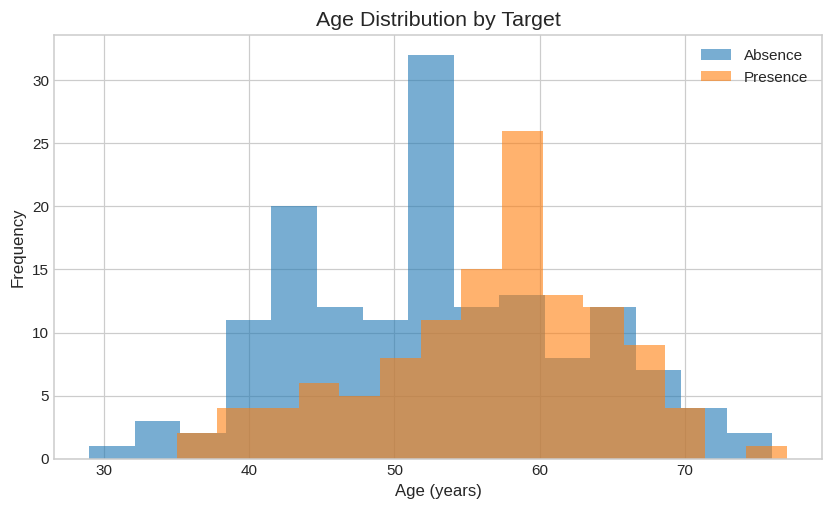

In [21]:
fig, ax = plt.subplots()
for label, name in [(0,"Absence"),(1,"Presence")]:
    ax.hist(df.loc[df.target==label,"age"], bins=15, alpha=.6, label=name)
ax.set(title="Age Distribution by Target", xlabel="Age (years)", ylabel="Frequency")
ax.legend()
plt.show()

## 22. Explore resting blood pressure
Examine the dataset and build the classification workflow step by step.

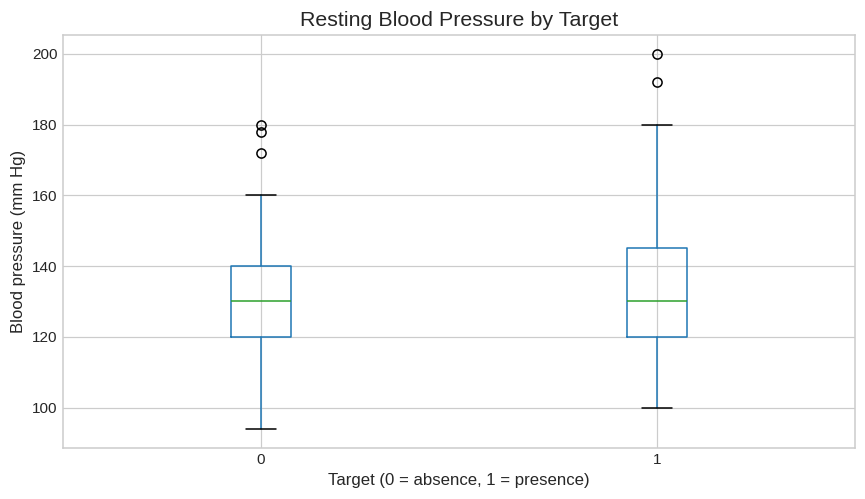

In [22]:
fig, ax = plt.subplots()
df.boxplot(column="trestbps", by="target", ax=ax)
ax.set(title="Resting Blood Pressure by Target", xlabel="Target (0 = absence, 1 = presence)", ylabel="Blood pressure (mm Hg)")
plt.suptitle("")
plt.show()

## 23. Explore cholesterol
Examine the dataset and build the classification workflow step by step.

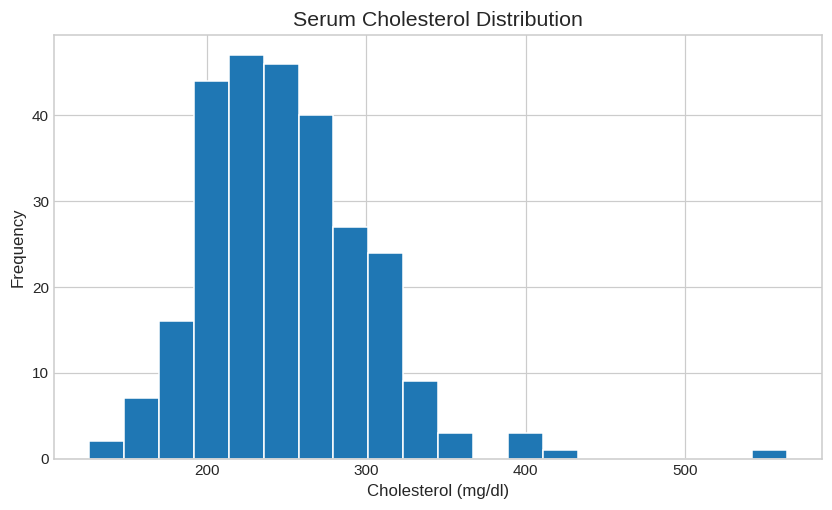

Range: 126 to 564


In [23]:
fig, ax = plt.subplots()
ax.hist(df.chol, bins=20, edgecolor="white")
ax.set(title="Serum Cholesterol Distribution", xlabel="Cholesterol (mg/dl)", ylabel="Frequency")
plt.show()
print("Range:", df.chol.min(), "to", df.chol.max())

## 24. Explore maximum heart rate
Examine the dataset and build the classification workflow step by step.

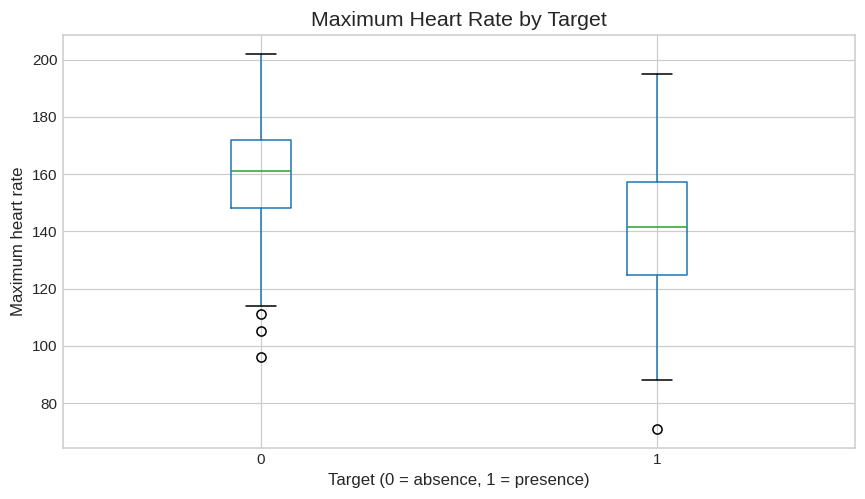

In [24]:
fig, ax = plt.subplots()
df.boxplot(column="thalach", by="target", ax=ax)
ax.set(title="Maximum Heart Rate by Target", xlabel="Target (0 = absence, 1 = presence)", ylabel="Maximum heart rate")
plt.suptitle("")
plt.show()

## 25. Explore ST depression
Examine the dataset and build the classification workflow step by step.

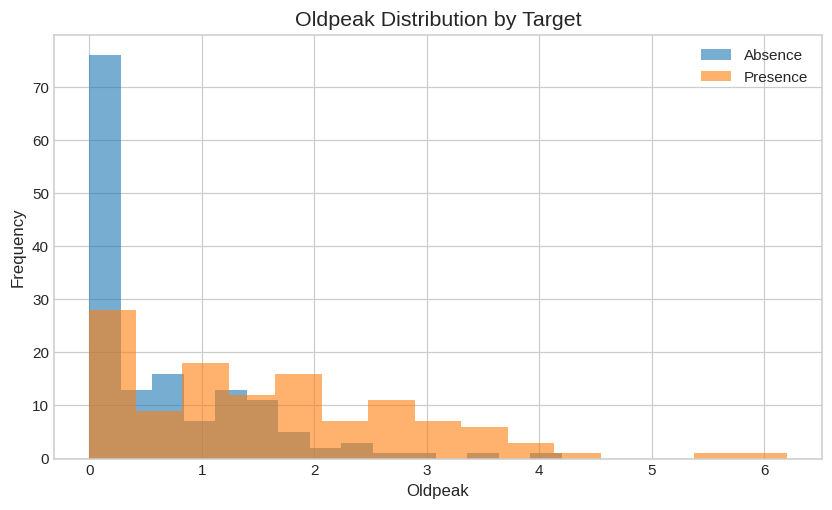

In [25]:
fig, ax = plt.subplots()
for label, name in [(0,"Absence"),(1,"Presence")]:
    ax.hist(df.loc[df.target==label,"oldpeak"], bins=15, alpha=.6, label=name)
ax.set(title="Oldpeak Distribution by Target", xlabel="Oldpeak", ylabel="Frequency")
ax.legend()
plt.show()

## 26. Inspect nominal feature counts
Examine the dataset and build the classification workflow step by step.

In [26]:
for col in CATEGORICAL_FEATURES:
    print("\n", col)
    display(df[col].value_counts().sort_index().to_frame("count"))


 sex


,count
sex,
0,87
1,183



 cp


,count
cp,
0,20
1,42
2,79
3,129



 fbs


,count
fbs,
0,230
1,40


... (6 outputs left out)


 ca


,count
ca,
0,160
1,58
2,33
3,19



 thal


,count
thal,
1,152
2,14
3,104


## 27. Chest pain category analysis
Examine the dataset and build the classification workflow step by step.

target,Absence %,Presence %
cp,,
0,75.0,25.0
1,83.3,16.7
2,78.5,21.5
3,29.5,70.5


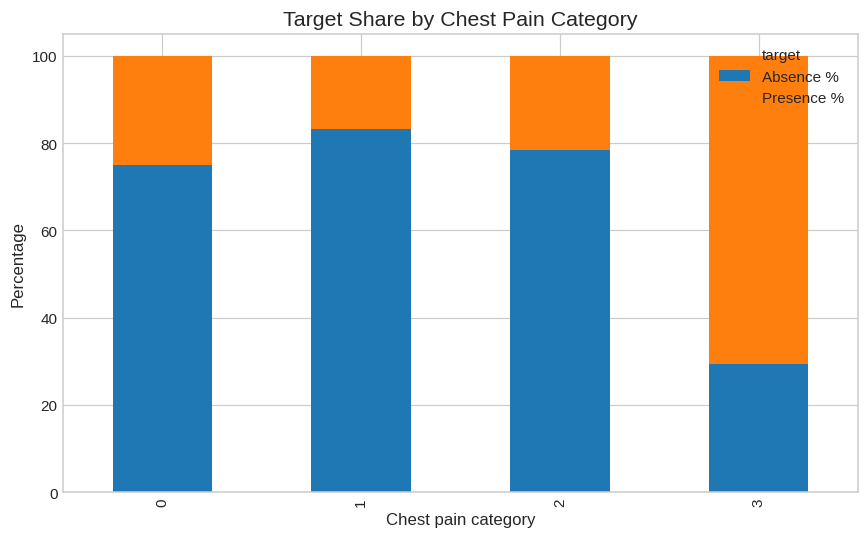

In [27]:
cp_share = pd.crosstab(df.cp, df.target, normalize="index")*100
cp_share = cp_share.rename(columns={0:"Absence %",1:"Presence %"})
display(cp_share.round(1))
cp_share.plot(kind="bar", stacked=True, figsize=(8,5))
plt.title("Target Share by Chest Pain Category")
plt.xlabel("Chest pain category")
plt.ylabel("Percentage")
plt.tight_layout()
plt.show()

## 28. Correlation matrix
Examine the dataset and build the classification workflow step by step.

In [28]:
correlation = df.corr(numeric_only=True)
display(correlation.round(2))

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
age,1.00,-0.09,0.10,0.27,0.22,0.12,0.13,-0.40,0.10,0.19,0.16,0.36,0.10,0.21
sex,-0.09,1.00,0.03,-0.06,-0.20,0.04,0.04,-0.08,0.18,0.10,0.05,0.09,0.38,0.30
cp,0.10,0.03,1.00,-0.04,0.09,-0.10,0.07,-0.32,0.35,0.17,0.14,0.23,0.27,0.42
trestbps,0.27,-0.06,-0.04,1.00,0.17,0.16,0.12,-0.04,0.08,0.22,0.14,0.09,0.13,0.16
chol,0.22,-0.20,0.09,0.17,1.00,0.03,0.17,-0.02,0.08,0.03,-0.01,0.13,0.04,0.12
fbs,0.12,0.04,-0.10,0.16,0.03,1.00,0.05,0.02,-0.00,-0.03,0.04,0.12,0.04,-0.02
restecg,0.13,0.04,0.07,0.12,0.17,0.05,1.00,-0.07,0.10,0.12,0.16,0.11,0.00,0.18
thalach,-0.40,-0.08,-0.32,-0.04,-0.02,0.02,-0.07,1.00,-0.38,-0.35,-0.39,-0.27,-0.24,-0.42
exang,0.10,0.18,0.35,0.08,0.08,-0.00,0.10,-0.38,1.00,0.27,0.26,0.15,0.32,0.42
oldpeak,0.19,0.10,0.17,0.22,0.03,-0.03,0.12,-0.35,0.27,1.00,0.61,0.26,0.33,0.42


## 29. Correlation heatmap
Examine the dataset and build the classification workflow step by step.

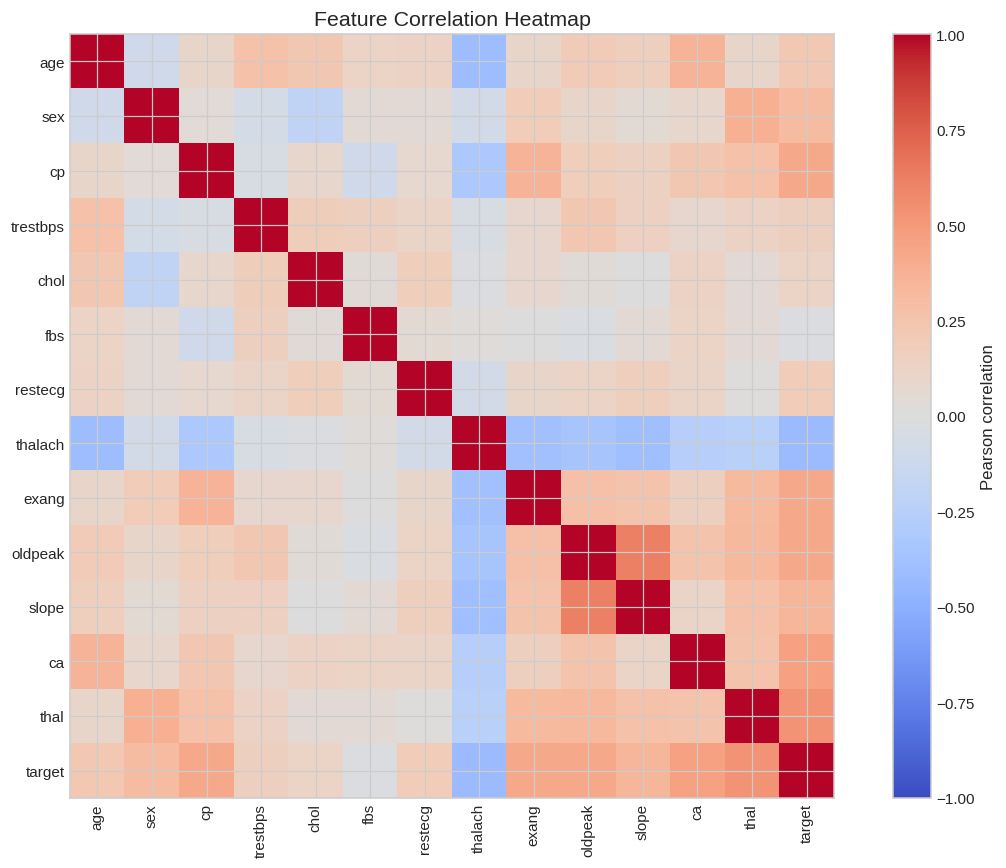

In [29]:
fig, ax = plt.subplots(figsize=(11,8))
im = ax.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(correlation.columns)))
ax.set_yticks(range(len(correlation.columns)))
ax.set_xticklabels(correlation.columns, rotation=90)
ax.set_yticklabels(correlation.columns)
ax.set_title("Feature Correlation Heatmap")
fig.colorbar(im, ax=ax, label="Pearson correlation")
plt.tight_layout()
plt.show()

## 30. Review numeric ranges and IQR
Examine the dataset and build the classification workflow step by step.

In [30]:
ranges = df[NUMERIC_FEATURES].describe().T
ranges["IQR"] = ranges["75%"] - ranges["25%"]
display(ranges[["min","25%","50%","75%","max","IQR"]].round(2))

,min,25%,50%,75%,max,IQR
age,29.0,48.0,55.0,61.0,77.0,13.0
trestbps,94.0,120.0,130.0,140.0,200.0,20.0
chol,126.0,213.0,245.0,280.0,564.0,67.0
thalach,71.0,133.0,153.5,166.0,202.0,33.0
oldpeak,0.0,0.0,0.8,1.6,6.2,1.6


## 31. Split features and target
Use a stratified split so class proportions remain similar in train and test data.

In [31]:
from sklearn.model_selection import train_test_split
X = df.drop(columns=TARGET)
y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=.20, random_state=RANDOM_STATE, stratify=y
)
print("Train:", X_train.shape, "| Test:", X_test.shape)
display(y_train.value_counts(normalize=True).sort_index().round(3).to_frame("train_share"))
display(y_test.value_counts(normalize=True).sort_index().round(3).to_frame("test_share"))

Train: (216, 13) | Test: (54, 13)


,train_share
target,
0,0.556
1,0.444


,test_share
target,
0,0.556
1,0.444


## 32. Create preprocessing pipeline
Scale numeric columns and one-hot encode nominal columns inside a pipeline to avoid leakage.

In [32]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

preprocessor = ColumnTransformer([
    ("numeric", StandardScaler(), NUMERIC_FEATURES),
    ("categorical", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL_FEATURES)
])
print("Scaling and one-hot encoding pipeline created.")

Scaling and one-hot encoding pipeline created.


## 33. Establish a majority-class baseline
Examine the dataset and build the classification workflow step by step.

In [33]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)
print("Accuracy:", round(accuracy_score(y_test, baseline_pred),4))
print("Recall:", round(recall_score(y_test, baseline_pred, zero_division=0),4))
print("F1:", round(f1_score(y_test, baseline_pred, zero_division=0),4))

Accuracy: 0.5556
Recall: 0.0
F1: 0.0


## 34. Train Logistic Regression
Examine the dataset and build the classification workflow step by step.

In [34]:
from sklearn.linear_model import LogisticRegression
logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
])
logistic_model.fit(X_train, y_train)
logistic_pred = logistic_model.predict(X_test)
print("Logistic Regression trained.")

Logistic Regression trained.


## 35. Evaluate Logistic Regression
Examine the dataset and build the classification workflow step by step.

              precision    recall  f1-score   support

     Absence       0.93      0.83      0.88        30
    Presence       0.81      0.92      0.86        24

    accuracy                           0.87        54
   macro avg       0.87      0.88      0.87        54
weighted avg       0.88      0.87      0.87        54



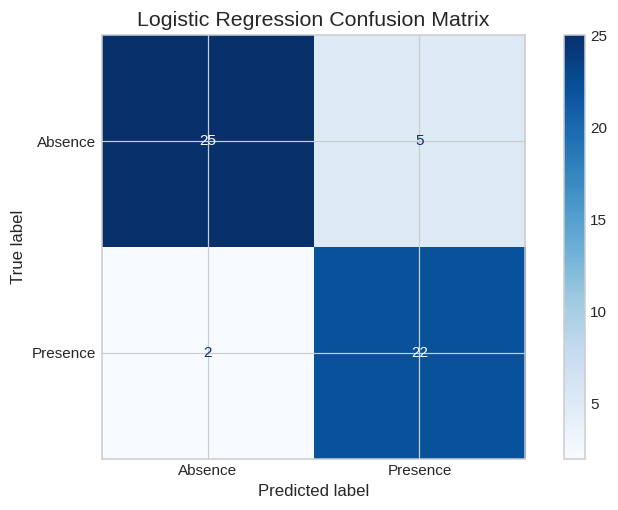

In [35]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
print(classification_report(y_test, logistic_pred, target_names=["Absence","Presence"], zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, logistic_pred, display_labels=["Absence","Presence"], cmap="Blues")
plt.title("Logistic Regression Confusion Matrix")
plt.show()

## 36. Train Decision Tree
Examine the dataset and build the classification workflow step by step.

In [36]:
from sklearn.tree import DecisionTreeClassifier
tree_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(max_depth=4, min_samples_leaf=4, random_state=RANDOM_STATE))
])
tree_model.fit(X_train, y_train)
tree_pred = tree_model.predict(X_test)
print("Decision Tree trained.")

Decision Tree trained.


## 37. Train Random Forest
Examine the dataset and build the classification workflow step by step.

In [37]:
from sklearn.ensemble import RandomForestClassifier
forest_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(n_estimators=180, max_depth=5,
        min_samples_leaf=3, random_state=RANDOM_STATE, n_jobs=-1))
])
forest_model.fit(X_train, y_train)
forest_pred = forest_model.predict(X_test)
print("Random Forest trained.")

Random Forest trained.


## 38. Train Support Vector Machine
Examine the dataset and build the classification workflow step by step.

In [38]:
from sklearn.svm import SVC
svm_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", SVC(kernel="rbf", C=1.0, probability=True, random_state=RANDOM_STATE))
])
svm_model.fit(X_train, y_train)
svm_pred = svm_model.predict(X_test)
print("SVM trained.")

SVM trained.


## 39. Train K-Nearest Neighbors
Examine the dataset and build the classification workflow step by step.

In [39]:
from sklearn.neighbors import KNeighborsClassifier
knn_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", KNeighborsClassifier(n_neighbors=7))
])
knn_model.fit(X_train, y_train)
knn_pred = knn_model.predict(X_test)
print("KNN trained.")

KNN trained.


## 40. Compare classification metrics
Examine the dataset and build the classification workflow step by step.

In [40]:
predictions = {
    "Logistic Regression": logistic_pred,
    "Decision Tree": tree_pred,
    "Random Forest": forest_pred,
    "SVM": svm_pred,
    "KNN": knn_pred
}
rows = []
for name, pred in predictions.items():
    rows.append({"Model":name, "Accuracy":accuracy_score(y_test,pred),
                 "Precision":precision_score(y_test,pred,zero_division=0),
                 "Recall":recall_score(y_test,pred,zero_division=0),
                 "F1-score":f1_score(y_test,pred,zero_division=0)})
results = pd.DataFrame(rows).set_index("Model").sort_values("F1-score", ascending=False)
display(results.round(4))

,Accuracy,Precision,Recall,F1-score
Model,,,,
Logistic Regression,0.8704,0.8148,0.9167,0.8627
SVM,0.8519,0.7857,0.9167,0.8462
KNN,0.8333,0.7778,0.8750,0.8235
Random Forest,0.8148,0.7917,0.7917,0.7917
Decision Tree,0.7963,0.7407,0.8333,0.7843


## 41. Plot model comparison
Examine the dataset and build the classification workflow step by step.

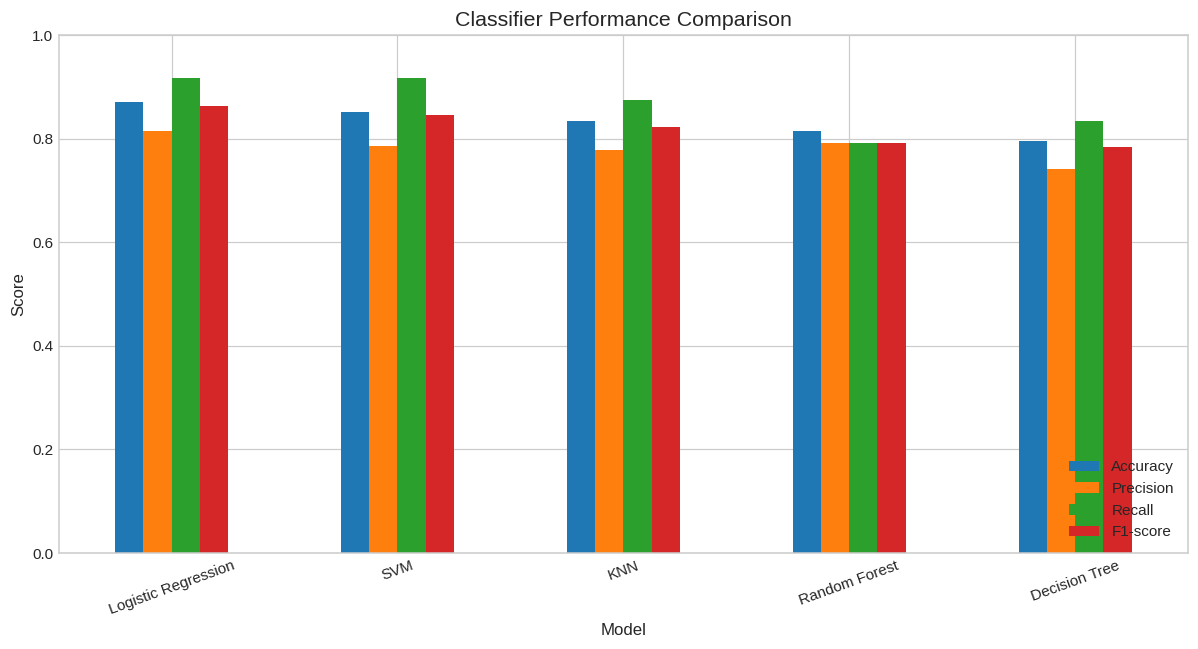

In [41]:
results.plot(kind="bar", figsize=(11,6), ylim=(0,1), rot=20)
plt.title("Classifier Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 42. Evaluate ROC-AUC
Examine the dataset and build the classification workflow step by step.

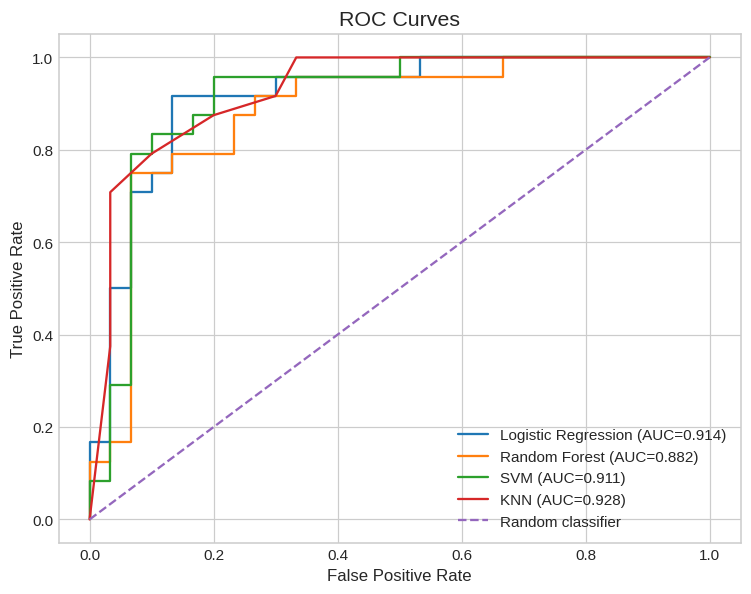

,ROC-AUC
KNN,0.9278
Logistic Regression,0.9139
SVM,0.9111
Random Forest,0.8819


In [42]:
from sklearn.metrics import roc_auc_score, roc_curve
probability_models = {"Logistic Regression":logistic_model, "Random Forest":forest_model,
                      "SVM":svm_model, "KNN":knn_model}
auc_scores = {}
fig, ax = plt.subplots(figsize=(8,6))
for name, model in probability_models.items():
    prob = model.predict_proba(X_test)[:,1]
    auc_scores[name] = roc_auc_score(y_test, prob)
    fpr, tpr, _ = roc_curve(y_test, prob)
    ax.plot(fpr, tpr, label=f"{name} (AUC={auc_scores[name]:.3f})")
ax.plot([0,1],[0,1],"--",label="Random classifier")
ax.set(title="ROC Curves", xlabel="False Positive Rate", ylabel="True Positive Rate")
ax.legend()
plt.show()
display(pd.Series(auc_scores, name="ROC-AUC").sort_values(ascending=False).round(4).to_frame())

## 43. Evaluate the supplied cost matrix
The documented matrix penalizes a false negative (missed presence) 50 times as much as a false positive.

In [43]:
# Rows = true class; columns = predicted class.
# Order: absence (0), presence (1).
# False positive cost = 1; false negative cost = 50.
COST_MATRIX = np.array([[0,1],[50,0]])

def total_cost(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred, labels=[0,1])
    return int(np.sum(cm * COST_MATRIX))

cost_rows = []
for name, pred in predictions.items():
    cm = confusion_matrix(y_test, pred, labels=[0,1])
    cost_rows.append({"Model":name, "False negatives":int(cm[1,0]),
                      "False positives":int(cm[0,1]), "Total cost":total_cost(y_test,pred)})
cost_results = pd.DataFrame(cost_rows).set_index("Model").sort_values("Total cost")
display(cost_results)

,False negatives,False positives,Total cost
Model,,,
Logistic Regression,2,5,105
SVM,2,6,106
KNN,3,6,156
Decision Tree,4,7,207
Random Forest,5,5,255


## 44. Analyze probability thresholds
Lower thresholds can improve sensitivity but may increase false positives; threshold selection needs validation.

In [44]:
logistic_prob = logistic_model.predict_proba(X_test)[:,1]
threshold_rows = []
for threshold in np.arange(.20,.81,.05):
    pred = (logistic_prob >= threshold).astype(int)
    cm = confusion_matrix(y_test, pred, labels=[0,1])
    threshold_rows.append({"Threshold":round(float(threshold),2),
        "Recall":recall_score(y_test,pred,zero_division=0),
        "Precision":precision_score(y_test,pred,zero_division=0),
        "F1-score":f1_score(y_test,pred,zero_division=0),
        "False negatives":int(cm[1,0]), "False positives":int(cm[0,1]),
        "Total cost":total_cost(y_test,pred)})
threshold_results = pd.DataFrame(threshold_rows)
display(threshold_results.round(3))

,Threshold,Recall,Precision,F1-score,False negatives,False positives,Total cost
0,0.20,0.958,0.697,0.807,1,10,60
1,0.25,0.958,0.697,0.807,1,10,60
2,0.30,0.958,0.719,0.821,1,9,59
3,0.35,0.917,0.759,0.830,2,7,107
4,0.40,0.917,0.759,0.830,2,7,107
5,0.45,0.917,0.786,0.846,2,6,106
6,0.50,0.917,0.815,0.863,2,5,105
7,0.55,0.917,0.815,0.863,2,5,105
8,0.60,0.917,0.846,0.880,2,4,104
9,0.65,0.917,0.846,0.880,2,4,104


## 45. Final model review and limitations
Examine the dataset and build the classification workflow step by step.

In [45]:
best_f1 = results["F1-score"].idxmax()
best_recall = results["Recall"].idxmax()
best_auc = max(auc_scores, key=auc_scores.get)
best_cost = cost_results["Total cost"].idxmin()

print("FINAL RESULTS")
print("-"*45)
print(f"Observations: {len(df)}")
print(f"Predictors: {X.shape[1]}")
print(f"Top F1 model: {best_f1} ({results.loc[best_f1,'F1-score']:.3f})")
print(f"Top recall model: {best_recall} ({results.loc[best_recall,'Recall']:.3f})")
print(f"Top ROC-AUC model: {best_auc} ({auc_scores[best_auc]:.3f})")
print(f"Lowest cost model on this split: {best_cost} (cost={cost_results.loc[best_cost,'Total cost']})")
print("\nLimitations:")
print("1. The dataset contains only 270 observations.")
print("2. A single holdout split can produce unstable performance estimates.")
print("3. The dataset is historical and may not represent current populations.")
print("4. These predictions are educational outputs, not medical diagnoses.")
print("5. Clinical deployment requires external validation, calibration, fairness")
print("   assessment, governance, and qualified medical oversight.")

FINAL RESULTS
---------------------------------------------
Observations: 270
Predictors: 13
Top F1 model: Logistic Regression (0.863)
Top recall model: Logistic Regression (0.917)
Top ROC-AUC model: KNN (0.928)
Lowest cost model on this split: Logistic Regression (cost=105)

Limitations:
1. The dataset contains only 270 observations.
2. A single holdout split can produce unstable performance estimates.
3. The dataset is historical and may not represent current populations.
4. These predictions are educational outputs, not medical diagnoses.
5. Clinical deployment requires external validation, calibration, fairness
   assessment, governance, and qualified medical oversight.


<div style="background:linear-gradient(120deg,#071a2f,#123b55,#087e8b);padding:25px;border-radius:15px;color:white;text-align:center">
<h2 style="color:white">Notebook Completed</h2>
<p>Statlog Heart Disease — EDA, Classification & Cost-Sensitive Evaluation</p>
<p><b>Prepared by Mobeen Fatima</b></p>
</div>

### Final takeaway
The workflow compares multiple classifiers and evaluates them using class-sensitive metrics and the supplied error-cost matrix. Model choice depends on the objective; accuracy alone is not sufficient when false negatives carry a much higher stated penalty.

**Reminder:** This is a small historical dataset. Results do not establish clinical reliability and must not be interpreted as medical advice.